# Projected density of states — `PDOSPlotter`

`PDOSPlotter` (in `cp2k_utils.new_pdos`) reads CP2K `.pdos` files, applies Gaussian smearing, and plots:
- **`plot_individual()`**: one figure per element, split into s / p / d / f contributions. Saved as `<element>_DOS.png`.
- **`plot_total()`**: every element's total on one figure. Saved as `output`.
- **`plot_ipr()`**: the total plot with the inverse participation ratio (IPR) of each state as sticks on a second y-axis. Saved as `DOS_IPR.png`.

Energies are shifted so that the Fermi energy in the PDOS header is at 0 eV. Element colours come from `cp2k_utils.Elements.ELEMENT_COLOURS`.

> The files in `data/pdos/` are **illustrative only**. They are not a real calculation. `data/make_example_pdos.py` writes them in CP2K's format to imitate N-doped HfO$_2$: an O-p valence band, a Hf-d conduction band and a localised N-p gap state. To use your own run, point `os.chdir` below at the folder containing your `.pdos` files.

## Required files

The plotter looks in the **current working directory** for:

| case | files matched for the k-th element |
|---|---|
| spin polarised (`spin=True`) | `*ALPHA_k<k>*` and `*BETA_k<k>*` |
| not spin polarised (`spin=False`) | `*k<k>*.pdos` |
| IPR (`plot_ipr`) | `IPR_output-Alpha.dat` and `IPR_output-Beta.dat` (two columns: eigenvalue in Ha, IPR) |

Elements must be listed **in the order of their CP2K `KIND` index**. If Hf is `k1` and O is `k2`, pass `['Hf', 'O']`.

In [1]:
import os
os.chdir('data/pdos')   # replace with the folder containing your own .pdos files
sorted(f for f in os.listdir() if not f.startswith('.'))

['DOS_IPR.png',
 'HfO2_N-ALPHA_k1-1_0.pdos',
 'HfO2_N-ALPHA_k2-1_0.pdos',
 'HfO2_N-ALPHA_k3-1_0.pdos',
 'HfO2_N-BETA_k1-1_0.pdos',
 'HfO2_N-BETA_k2-1_0.pdos',
 'HfO2_N-BETA_k3-1_0.pdos',
 'HfO2_N_DOS.png',
 'Hf_DOS.png',
 'Hf_alpha_smeared.dat',
 'IPR_output-Alpha.dat',
 'IPR_output-Beta.dat',
 'N_DOS.png',
 'O_DOS.png']

In [2]:
from cp2k_utils.new_pdos import PDOSPlotter

## Options

| argument | default | |
|---|---|---|
| `elements` | required | element symbols in KIND order |
| `spin` | `True` | spin-polarised calculation (beta channel drawn as negative) |
| `sigma` | `0.003` | Gaussian smearing width (Ha) |
| `vbm` | `0` | position of the dashed vertical marker (eV) |
| `grid` | `False` | |
| `xmin`, `xmax` | `-3`, `6` | energy window (eV); the y-scale is fitted to this window |
| `figw`, `figh` | `25`, `10` | figure size |
| `output` | `'DOS.png'` | file name for `plot_total()` |

In [3]:
dos = PDOSPlotter(['Hf', 'O', 'N'], spin=True, sigma=0.003,
                  xmin=-4, xmax=8, figw=15, figh=8, output='HfO2_N_DOS.png')

### Per-element, orbital-resolved

Alpha (spin up) is plotted above zero and beta (spin down) below. The y-scale is fitted to the largest value in the `xmin`–`xmax` window.

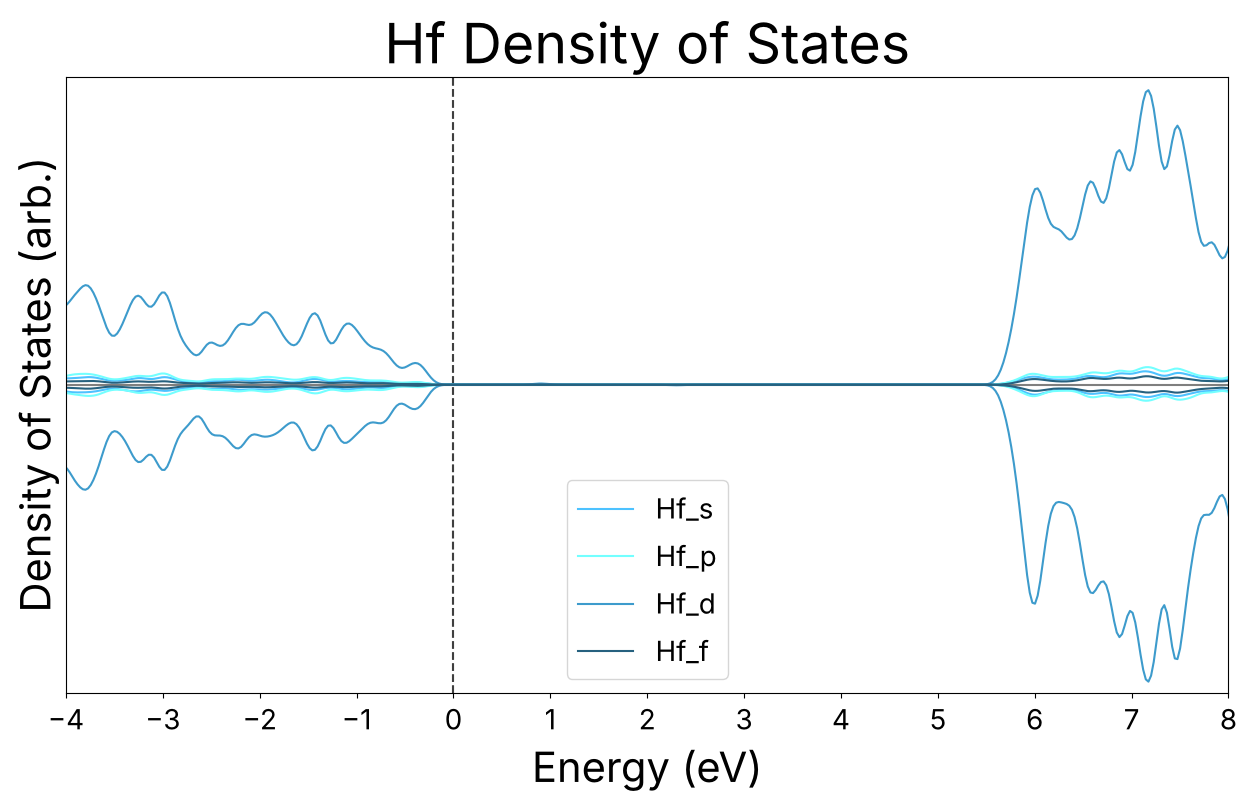

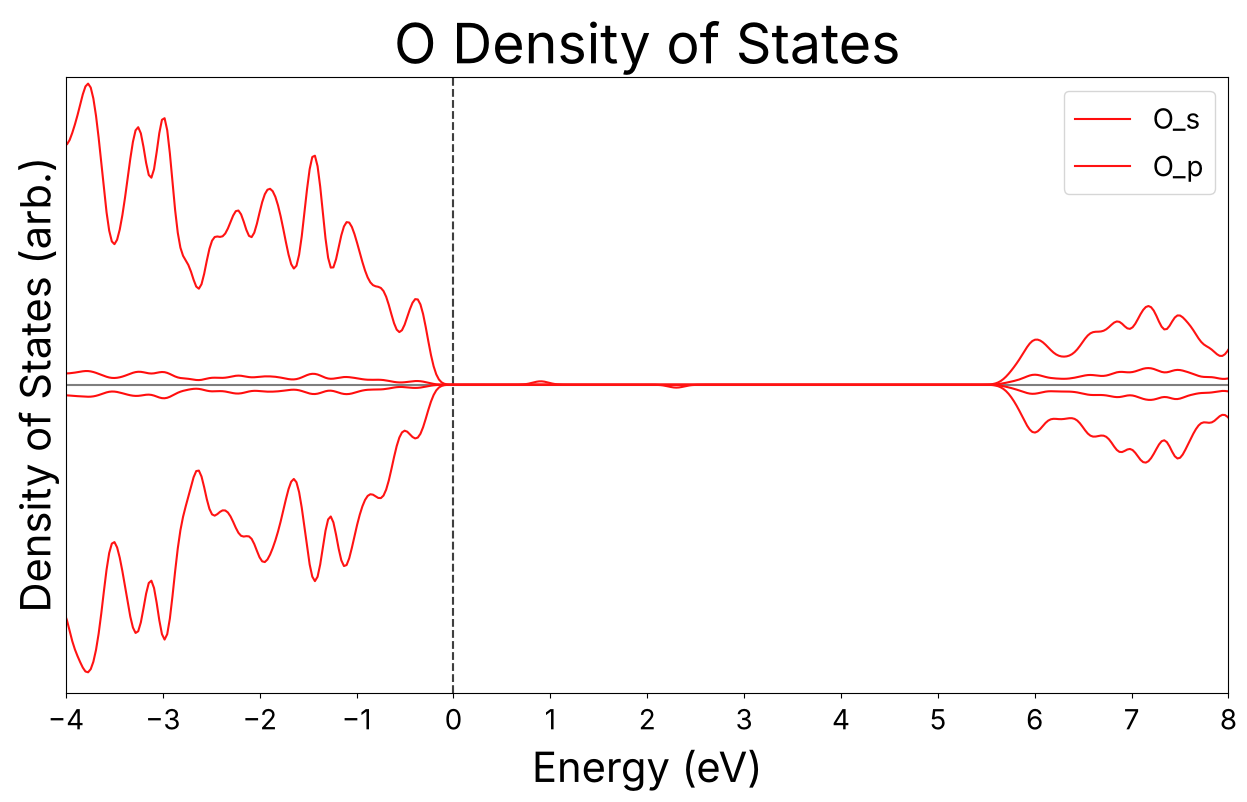

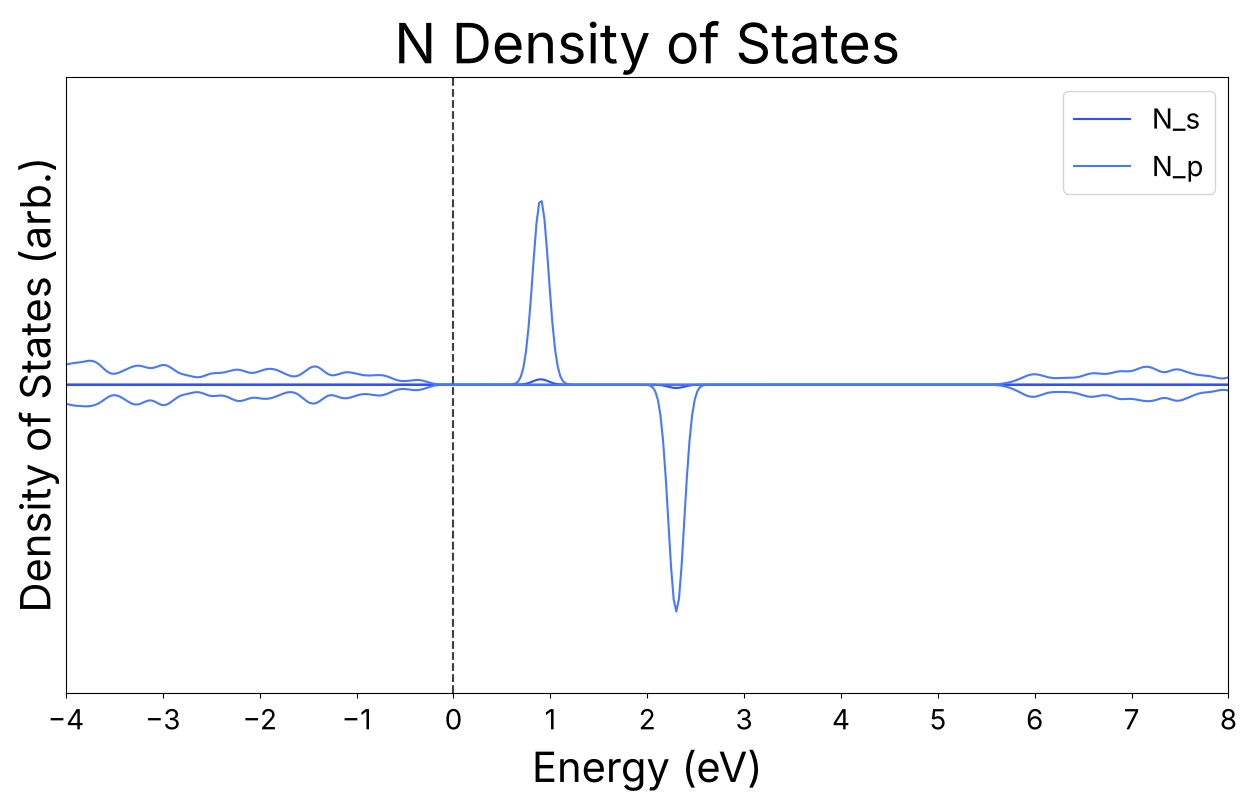

In [4]:
dos.plot_individual()

### Total, one line per element

The occupied N state at ~0.9 eV (alpha) and the empty one at ~2.3 eV (beta) can be seen in the gap.

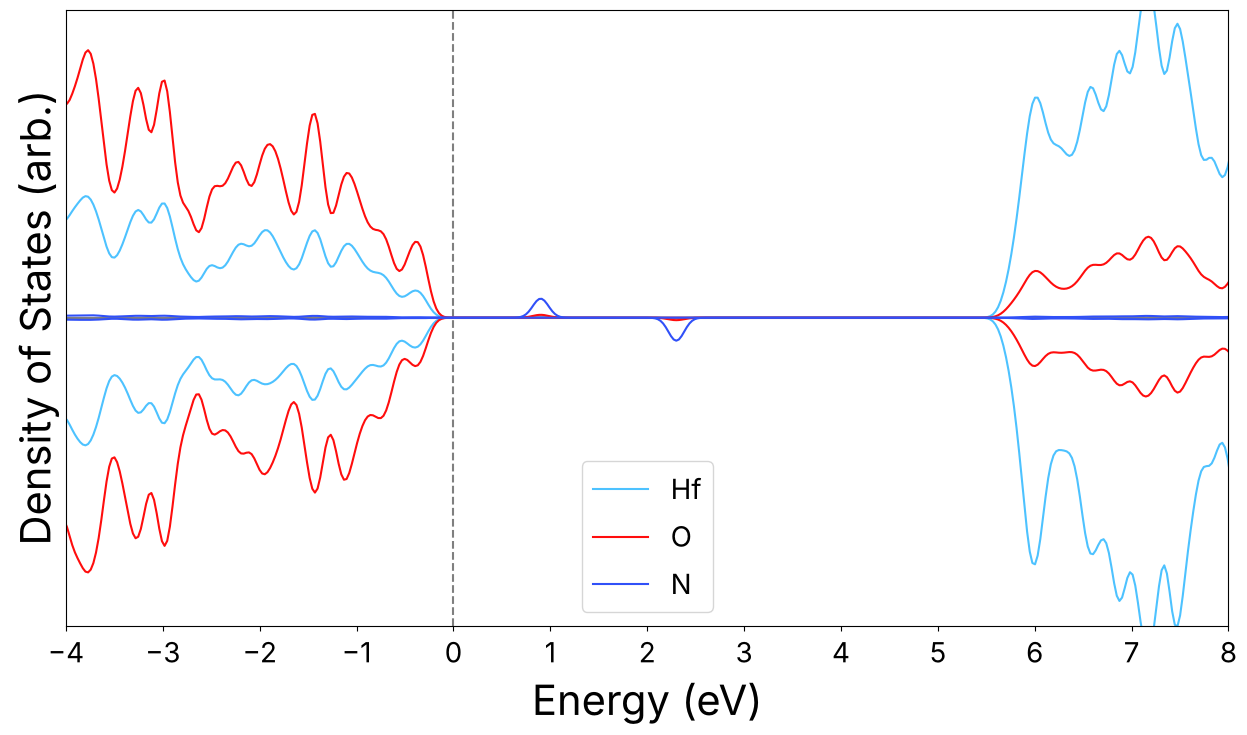

In [5]:
dos.plot_total()

### With IPR

The IPR of each Kohn-Sham state is drawn as a black stick on a second axis. Localised states (here the N gap states) have much larger IPR than the delocalised band states.

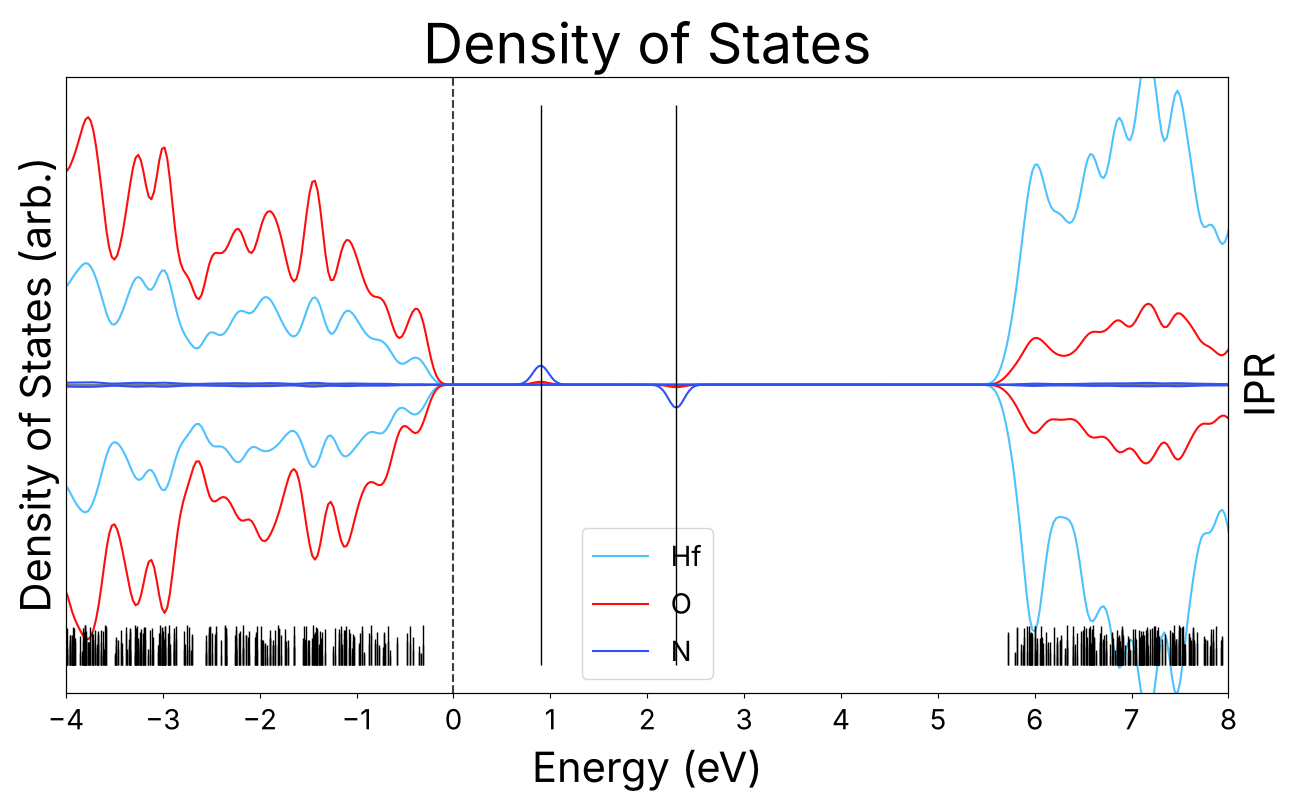

In [6]:
dos.plot_ipr()   # or dos.plot_ipr('alpha_file.dat', 'beta_file.dat')

## Smeared data without plotting

`smeared_pdos` returns the smeared data as a list of rows: a header row, then `[energy_eV, orbital1, orbital2, ...]`. It can also write the data to a text file.

In [7]:
from cp2k_utils.new_pdos import smeared_pdos

rows = smeared_pdos(['HfO2_N-ALPHA_k1-1_0.pdos'], sigma=0.003, output='Hf_alpha_smeared.dat')
print(rows[0])   # header
print(rows[1])   # first data row

['Energy_[eV]', 's', 'p', 'd', 'f']
[np.float64(-7.256813519272), np.float64(5.7411803086185e-25), np.float64(1.0253741928663722e-24), np.float64(6.078359025445722e-24), np.float64(2.3398930046812433e-25)]


## Legacy function

The older one-call function is still in `cp2k_utils.pdos` (and `new_pdos`):

```python
from cp2k_utils.pdos import pdos_plot
pdos_plot(['Hf', 'O', 'N', 'H'], sigma=0.0015, vbm=0, grid=False, xmin=-1, xmax=7, figw=15, figh=10)
```

`ipr_pdos_plot` takes the same arguments and adds the IPR overlay. New work should use `PDOSPlotter`.